# Object Detection auf TACO (Trash Annotations in Context)

Dieses Notebook trainiert einen Objektdetektor für Müll auf dem **TACO**-Datensatz (COCO-Format, ca. 1.500 Bilder, 60 Kategorien in 28 Superkategorien).

**Ablauf**
1. Setup & Download (TACO-Repo + Bilder)
2. Explorative Analyse (Klassenverteilung, Bildgrößen, Objektgrößen)
3. Klassen-Mapping (60 Klassen → Superkategorien / Top-N / binär)
4. Split nach Bildern (Train/Val/Test)
5. Konvertierung COCO → YOLO (inkl. EXIF-Korrektur & Downscaling)
6. Training mit Ultralytics YOLO (Transfer Learning)
7. Evaluation (mAP, pro Klasse, Confusion Matrix)
8. Inferenz & Visualisierung, Export nach ONNX

**Hardware:** Eine GPU ist dringend empfohlen (Colab T4 reicht für `yolo11s` bei `imgsz=640–1024`). Auf CPU läuft alles, das Training dauert aber Stunden.

## 1. Setup

In [1]:
# Einmalig ausführen (Linux / Colab)
!pip install -q ultralytics pycocotools pandas matplotlib seaborn requests pillow tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import os, json, random, shutil
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

# ---------------- Konfiguration ----------------
ROOT        = Path("taco_work").resolve()
TACO_REPO   = ROOT / "TACO"                  # geklontes GitHub-Repo
TACO_DATA   = TACO_REPO / "data"             # annotations.json + batch_*/
YOLO_DIR    = ROOT / "taco_yolo"             # Ausgabe im YOLO-Format

CLASS_MODE  = "super"   # "super" (28 Superkat.), "topN" (N häufigste + 'Other'), "binary" (nur 'litter'), "full" (60)
TOP_N       = 10
MAX_SIDE    = 1280      # Bilder beim Konvertieren verkleinern (TACO-Originale sind oft 3-4k px)
SPLIT       = (0.8, 0.1, 0.1)
SEED        = 42

MODEL_NAME  = "yolo11s.pt"   # Alternativen: yolo11n.pt (schnell), yolo11m.pt (genauer)
EPOCHS      = 100
IMGSZ       = 1024           # TACO hat viele kleine Objekte -> eher groß wählen
BATCH       = -1             # -1 = AutoBatch (passt sich an GPU-Speicher an)

random.seed(SEED); np.random.seed(SEED)
ROOT.mkdir(parents=True, exist_ok=True)
print(ROOT)

/mnt/NVME/bjoern/TACO-WESORT.AI/taco_work


### Daten herunterladen
Die Annotationen liegen im GitHub-Repo, die Bilder werden vom Download-Skript des Repos (Flickr-URLs) geladen. Das dauert je nach Verbindung eine Weile (~2–3 GB). Einzelne Flickr-Links können tot sein, fehlende Bilder werden später übersprungen.

In [3]:
if not TACO_REPO.exists():
    !git clone --depth 1 https://github.com/pedropro/TACO.git {TACO_REPO}

# Offizielles Download-Skript (lädt alle Bilder in data/batch_*/)
!cd {TACO_REPO} && python download.py

Klone nach '/mnt/NVME/bjoern/TACO-WESORT.AI/taco_work/TACO'...
remote: Enumerating objects: 31, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 31 (delta 2), reused 10 (delta 0), pack-reused 0 (from 0)
Empfange Objekte: 100% (31/31), 22.79 MiB | 4.64 MiB/s, fertig.
Löse Unterschiede auf: 100% (2/2), fertig.
/bin/bash: Zeile 1: python: Kommando nicht gefunden.


## 2. Explorative Analyse

In [4]:
with open(TACO_DATA / "annotations.json") as f:
    coco = json.load(f)

images = {im["id"]: im for im in coco["images"]}
cats   = {c["id"]: c for c in coco["categories"]}
anns   = coco["annotations"]

print(f"Bilder: {len(images)} | Annotationen: {len(anns)} | Kategorien: {len(cats)} | "
      f"Superkategorien: {len({c['supercategory'] for c in cats.values()})}")

df = pd.DataFrame([{
    "image_id": a["image_id"],
    "cat": cats[a["category_id"]]["name"],
    "super": cats[a["category_id"]]["supercategory"],
    "w": a["bbox"][2], "h": a["bbox"][3],
    "img_w": images[a["image_id"]]["width"], "img_h": images[a["image_id"]]["height"],
} for a in anns])
df["rel_area"] = (df.w * df.h) / (df.img_w * df.img_h)
df.head()

Bilder: 1500 | Annotationen: 4784 | Kategorien: 60 | Superkategorien: 28


,image_id,cat,super,w,h,img_w,img_h,rel_area
0,0,Glass bottle,Bottle,447.0,1322.0,1537,2049,0.187639
1,1,Meal carton,Carton,1429.0,1519.0,1537,2049,0.689246
2,1,Other carton,Carton,1006.0,672.0,1537,2049,0.214660
3,2,Clear plastic bottle,Bottle,500.0,374.0,1537,2049,0.059378
4,2,Plastic bottle cap,Bottle cap,44.0,51.0,1537,2049,0.000713


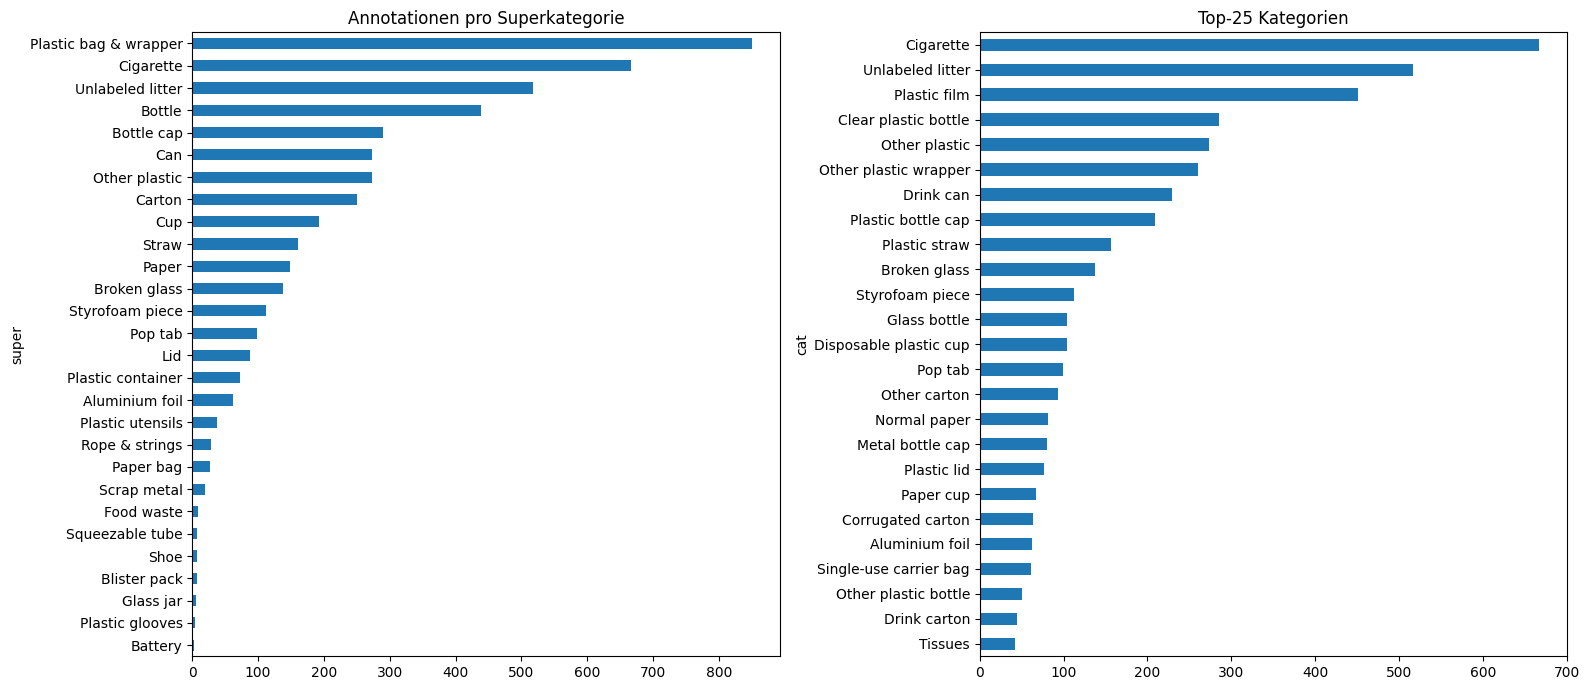

Objekte pro Bild:
 count    1500.00
mean        3.19
std         4.69
min         1.00
25%         1.00
50%         2.00
75%         3.00
max        90.00
dtype: float64

Relative Objektfläche (Anteil am Bild):
 count    4784.0000
mean        0.0275
std         0.0736
min         0.0000
10%         0.0002
25%         0.0005
50%         0.0035
75%         0.0176
max         0.9419
Name: rel_area, dtype: float64

Anteil sehr kleiner Objekte (<0.1% der Bildfläche): 33.8%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
df["super"].value_counts().plot.barh(ax=axes[0]); axes[0].invert_yaxis()
axes[0].set_title("Annotationen pro Superkategorie")
df["cat"].value_counts().head(25).plot.barh(ax=axes[1]); axes[1].invert_yaxis()
axes[1].set_title("Top-25 Kategorien")
plt.tight_layout(); plt.show()

print("Objekte pro Bild:\n", df.groupby("image_id").size().describe().round(2))
print("\nRelative Objektfläche (Anteil am Bild):\n", df["rel_area"].describe(percentiles=[.1,.25,.5,.75]).round(4))
print(f"\nAnteil sehr kleiner Objekte (<0.1% der Bildfläche): {(df.rel_area < 0.001).mean():.1%}")

**Typische Befunde:** starke Long-Tail-Verteilung (einige Klassen haben nur eine Handvoll Beispiele), viele kleine Objekte, hochauflösende Bilder. Deshalb: Klassen zusammenfassen und mit großer `imgsz` trainieren.

## 3. Klassen-Mapping

In [6]:
def build_class_mapping(mode=CLASS_MODE, top_n=TOP_N):
    # Gibt (names: list[str], cat_id -> class_idx | None) zurück
    if mode == "full":
        names = [cats[cid]["name"] for cid in sorted(cats)]
        return names, {cid: names.index(cats[cid]["name"]) for cid in cats}
    if mode == "super":
        names = sorted({c["supercategory"] for c in cats.values()})
        return names, {cid: names.index(c["supercategory"]) for cid, c in cats.items()}
    if mode == "topN":
        top = df["super"].value_counts().head(top_n).index.tolist()
        names = top + ["Other"]
        return names, {cid: (names.index(c["supercategory"]) if c["supercategory"] in top else len(top))
                       for cid, c in cats.items()}
    if mode == "binary":
        return ["litter"], {cid: 0 for cid in cats}
    raise ValueError(mode)

CLASS_NAMES, CAT2CLS = build_class_mapping()
print(len(CLASS_NAMES), "Klassen:", CLASS_NAMES)

28 Klassen: ['Aluminium foil', 'Battery', 'Blister pack', 'Bottle', 'Bottle cap', 'Broken glass', 'Can', 'Carton', 'Cigarette', 'Cup', 'Food waste', 'Glass jar', 'Lid', 'Other plastic', 'Paper', 'Paper bag', 'Plastic bag & wrapper', 'Plastic container', 'Plastic glooves', 'Plastic utensils', 'Pop tab', 'Rope & strings', 'Scrap metal', 'Shoe', 'Squeezable tube', 'Straw', 'Styrofoam piece', 'Unlabeled litter']


## 4. Split nach Bildern
Split auf Bild-Ebene (nie Annotationen eines Bildes auf mehrere Splits verteilen). Greedy-Verteilung, damit seltene Klassen möglichst in allen Splits vorkommen.

In [16]:
anns_by_img = defaultdict(list)
for a in anns:
    anns_by_img[a["image_id"]].append(a)

def split_images(img_ids, ratios=SPLIT, seed=SEED):
    rng = random.Random(seed)
    cls_freq = Counter(CAT2CLS[a["category_id"]] for a in anns)
    # Seltenste Klasse im Bild als Schlüssel -> Bilder mit seltenen Klassen zuerst verteilen
    def rarest(iid):
        cl = [CAT2CLS[a["category_id"]] for a in anns_by_img[iid]]
        return min((cls_freq[c] for c in cl), default=10**9)
    ids = list(img_ids); rng.shuffle(ids); ids.sort(key=rarest)
    names = ["train", "val", "test"]
    target = {n: r * len(ids) for n, r in zip(names, ratios)}
    out = {n: [] for n in names}
    cls_count = {n: Counter() for n in names}
    for iid in ids:
        cl = {CAT2CLS[a["category_id"]] for a in anns_by_img[iid]}
        # Split wählen, der relativ am "hungrigsten" für diese Klassen ist und noch Platz hat
        cand = [n for n in names if len(out[n]) < target[n]] or names
        best = min(cand, key=lambda n: (sum(cls_count[n][c] / max(target[n], 1) for c in cl),
                                        len(out[n]) / max(target[n], 1)))
        out[best].append(iid)
        for c in cl: cls_count[best][c] += 1
    return out

splits = split_images(images.keys())
print({k: len(v) for k, v in splits.items()})

{'train': 1200, 'val': 150, 'test': 150}


## 5. Konvertierung COCO → YOLO
Wichtige Details:
- **EXIF-Orientierung:** Viele TACO-Fotos sind per EXIF rotiert. Die Annotationen beziehen sich auf das *korrekt orientierte* Bild. Wir wenden `exif_transpose` an und speichern ohne EXIF, damit kein Tool doppelt dreht.
- **Downscaling** auf `MAX_SIDE` spart Platz und Ladezeit; YOLO-Labels sind normiert und daher skalierungsunabhängig.
- COCO-bbox `[x, y, w, h]` (absolut, oben links) → YOLO `cls cx cy w h` (normiert).

In [17]:
def coco_bbox_to_yolo(bbox, img_w, img_h):
    x, y, w, h = bbox
    # auf Bild clippen
    x0, y0 = max(0.0, x), max(0.0, y)
    x1, y1 = min(img_w, x + w), min(img_h, y + h)
    w, h = x1 - x0, y1 - y0
    if w <= 1 or h <= 1:
        return None
    return ((x0 + w / 2) / img_w, (y0 + h / 2) / img_h, w / img_w, h / img_h)


def convert_split(split_name, img_ids):
    img_out = YOLO_DIR / "images" / split_name
    lbl_out = YOLO_DIR / "labels" / split_name
    img_out.mkdir(parents=True, exist_ok=True); lbl_out.mkdir(parents=True, exist_ok=True)
    stats = Counter()
    for iid in tqdm(img_ids, desc=split_name):
        info = images[iid]
        src = TACO_DATA / info["file_name"]
        if not src.exists():
            stats["missing"] += 1; continue
        stem = info["file_name"].replace("/", "_").rsplit(".", 1)[0]
        dst_img = img_out / f"{stem}.jpg"

        im = ImageOps.exif_transpose(Image.open(src)).convert("RGB")
        W, H = im.size
        # Plausibilitätscheck gegen annotations.json
        if (W, H) != (info["width"], info["height"]):
            if (W, H) == (info["height"], info["width"]):
                stats["orientation_mismatch"] += 1   # Annotation passt zur Original-Orientierung
                im = Image.open(src).convert("RGB"); W, H = im.size
            else:
                stats["size_mismatch"] += 1
        scale = MAX_SIDE / max(W, H)
        if scale < 1:
            im = im.resize((round(W * scale), round(H * scale)), Image.LANCZOS)
        im.save(dst_img, quality=92)

        lines = []
        for a in anns_by_img[iid]:
            cls = CAT2CLS.get(a["category_id"])
            if cls is None: continue
            yb = coco_bbox_to_yolo(a["bbox"], W, H)
            if yb is None: stats["degenerate_box"] += 1; continue
            lines.append(f"{cls} " + " ".join(f"{v:.6f}" for v in yb))
        (lbl_out / f"{stem}.txt").write_text("\n".join(lines))
        stats["ok"] += 1
    return stats

if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
for s, ids in splits.items():
    print(s, dict(convert_split(s, ids)))

train:   0%|          | 0/1200 [00:00<?, ?it/s]

train {'ok': 1200}


val:   0%|          | 0/150 [00:00<?, ?it/s]

val {'ok': 150}


test:   0%|          | 0/150 [00:00<?, ?it/s]

test {'ok': 150}


In [18]:
DATA_YAML = YOLO_DIR / "taco.yaml"
DATA_YAML.write_text(
    f"path: {YOLO_DIR}\n"
    "train: images/train\nval: images/val\ntest: images/test\n"
    f"nc: {len(CLASS_NAMES)}\n"
    "names:\n" + "".join(f"  {i}: '{n}'\n" for i, n in enumerate(CLASS_NAMES))
)
print(DATA_YAML.read_text())

path: /mnt/NVME/bjoern/TACO-WESORT.AI/taco_work/taco_yolo
train: images/train
val: images/val
test: images/test
nc: 28
names:
  0: 'Aluminium foil'
  1: 'Battery'
  2: 'Blister pack'
  3: 'Bottle'
  4: 'Bottle cap'
  5: 'Broken glass'
  6: 'Can'
  7: 'Carton'
  8: 'Cigarette'
  9: 'Cup'
  10: 'Food waste'
  11: 'Glass jar'
  12: 'Lid'
  13: 'Other plastic'
  14: 'Paper'
  15: 'Paper bag'
  16: 'Plastic bag & wrapper'
  17: 'Plastic container'
  18: 'Plastic glooves'
  19: 'Plastic utensils'
  20: 'Pop tab'
  21: 'Rope & strings'
  22: 'Scrap metal'
  23: 'Shoe'
  24: 'Squeezable tube'
  25: 'Straw'
  26: 'Styrofoam piece'
  27: 'Unlabeled litter'



### Sichtprüfung der Labels
Vor dem Training immer prüfen, ob die Boxen sitzen (häufigster Fehler: Rotation/EXIF).

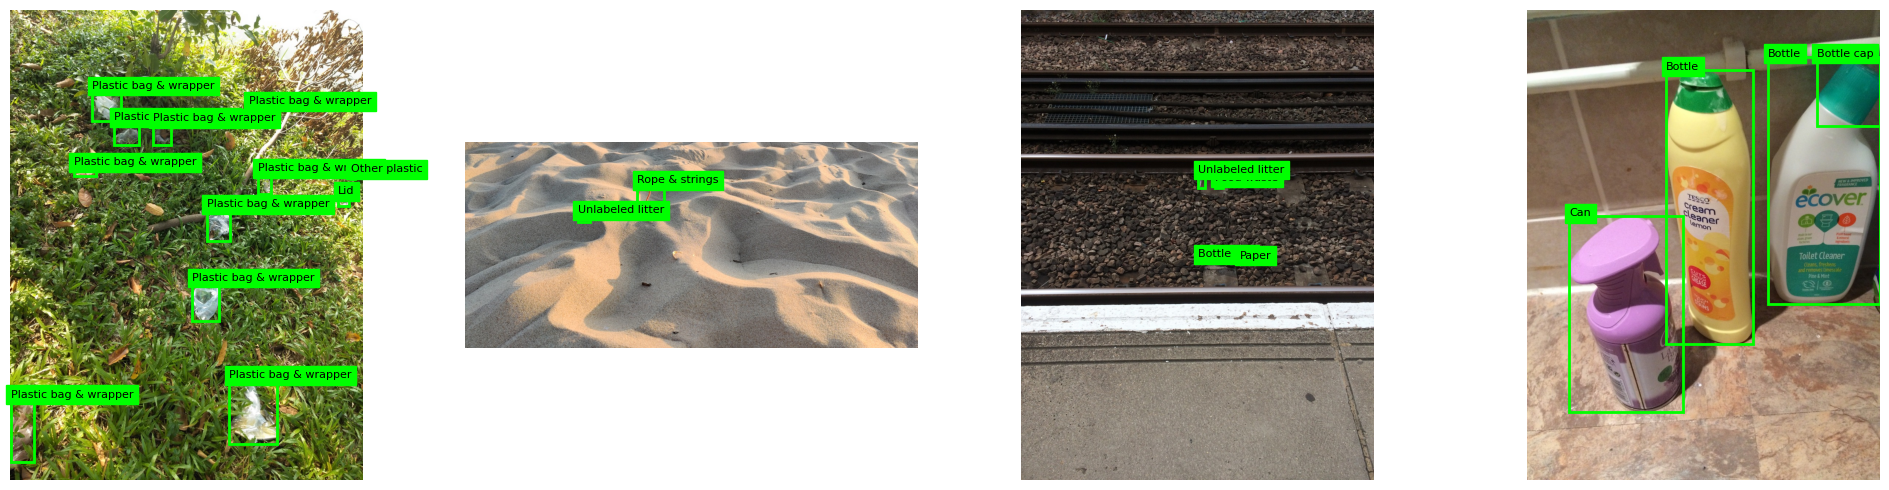

In [19]:
def show_yolo_sample(split="train", n=4):
    imgs = sorted((YOLO_DIR / "images" / split).glob("*.jpg"))
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    for ax, p in zip(axes, random.sample(imgs, n)):
        im = Image.open(p); W, H = im.size
        ax.imshow(im); ax.axis("off")
        for line in (YOLO_DIR / "labels" / split / f"{p.stem}.txt").read_text().splitlines():
            c, cx, cy, w, h = line.split(); c = int(c)
            cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
            ax.add_patch(plt.Rectangle((cx - w/2, cy - h/2), w, h, fill=False, color="lime", lw=2))
            ax.text(cx - w/2, cy - h/2, CLASS_NAMES[c], color="black", backgroundcolor="lime", fontsize=8)
    plt.tight_layout(); plt.show()

show_yolo_sample()

## 6. Training (Transfer Learning)
Vortrainierte COCO-Gewichte + Feintuning. Bei ~1.200 Trainingsbildern ist Transfer Learning Pflicht, Training from scratch funktioniert hier nicht sinnvoll.
Augmentierungen: Mosaic, Flip, HSV, Scale sind in Ultralytics standardmäßig aktiv; zusätzlich `flipud` und `degrees`, weil Müll keine feste Orientierung hat.

In [21]:
from ultralytics import YOLO

model = YOLO(MODEL_NAME)
results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=25,          # Early Stopping
    seed=SEED,
    project=str(ROOT / "runs"),
    name=f"taco_{CLASS_MODE}_{Path(MODEL_NAME).stem}",
    exist_ok=True,
    # Augmentierung
    flipud=0.5, fliplr=0.5, degrees=15, mosaic=1.0, close_mosaic=10,
    # Optimierung
    optimizer="auto", cos_lr=True,
    plots=True,
)
RUN_DIR = Path(results.save_dir)
BEST = RUN_DIR / "weights" / "best.pt"
print(BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/bjoern/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.9 torch-2.10.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/NVME/bjoern/TACO-WESORT.AI/taco_work/taco_yolo/taco.yaml, degrees=15, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0

## 7. Evaluation auf dem Test-Split

In [22]:
best = YOLO(BEST)
metrics = best.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, plots=True,
                   project=str(ROOT / "runs"), name="test_eval", exist_ok=True)

print(f"mAP50     : {metrics.box.map50:.3f}")
print(f"mAP50-95  : {metrics.box.map:.3f}")
print(f"Precision : {metrics.box.mp:.3f}")
print(f"Recall    : {metrics.box.mr:.3f}")

per_class = pd.DataFrame({
    "class": [CLASS_NAMES[i] for i in metrics.box.ap_class_index],
    "AP50": metrics.box.ap50,
    "AP50-95": metrics.box.ap,
})
n_train = Counter()
for p in (YOLO_DIR / "labels" / "train").glob("*.txt"):
    for line in p.read_text().splitlines():
        n_train[CLASS_NAMES[int(line.split()[0])]] += 1
per_class["n_train"] = per_class["class"].map(n_train)
per_class.sort_values("AP50", ascending=False).round(3)

Ultralytics 8.4.215 🚀 Python-3.13.9 torch-2.10.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 24083MiB)
YOLO11s summary (fused): 100 layers, 9,423,636 parameters, 0 gradients, 21.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6318.3±845.0 MB/s, size: 536.7 KB)
val: Scanning /mnt/NVME/bjoern/TACO-WESORT.AI/taco_work/taco_yolo/labels/test... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 4.7Kit/s 0.0s
val: New cache created: /mnt/NVME/bjoern/TACO-WESORT.AI/taco_work/taco_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 8.0it/s 1.3s0.2s
                   all        150        490      0.586      0.204      0.183      0.131
        Aluminium foil          4          4          1          0      0.146      0.117
          Blister pack          1          1          1          0          0          0
                Bottle         33         49      0.488      0.604      0.606     

,class,AP50,AP50-95,n_train
2,Bottle,0.606,0.405,338
3,Bottle cap,0.582,0.397,233
8,Cup,0.423,0.334,154
5,Can,0.366,0.268,216
20,Rope & strings,0.335,0.234,23
25,Styrofoam piece,0.329,0.234,87
11,Lid,0.326,0.247,69
24,Straw,0.310,0.200,137
6,Carton,0.292,0.170,200
15,Plastic bag & wrapper,0.274,0.183,706


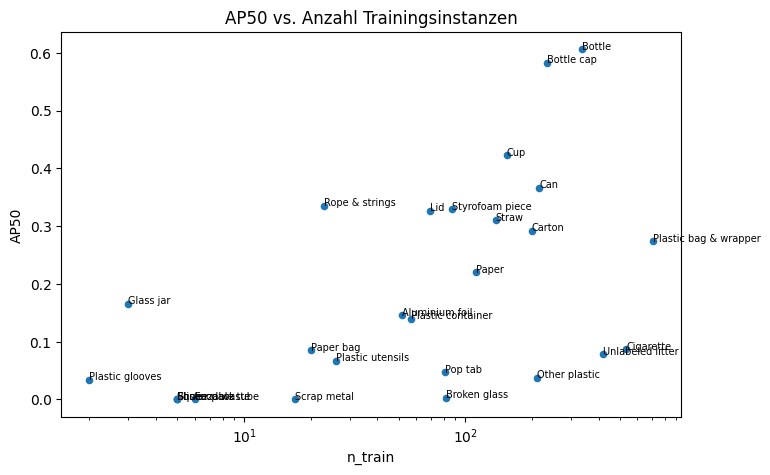

In [23]:
# Zusammenhang Trainingsmenge <-> AP: zeigt, wo mehr Daten am meisten bringen würden
ax = per_class.plot.scatter(x="n_train", y="AP50", logx=True, figsize=(8, 5))
for _, r in per_class.iterrows():
    ax.annotate(r["class"], (r["n_train"], r["AP50"]), fontsize=7)
ax.set_title("AP50 vs. Anzahl Trainingsinstanzen"); plt.show()

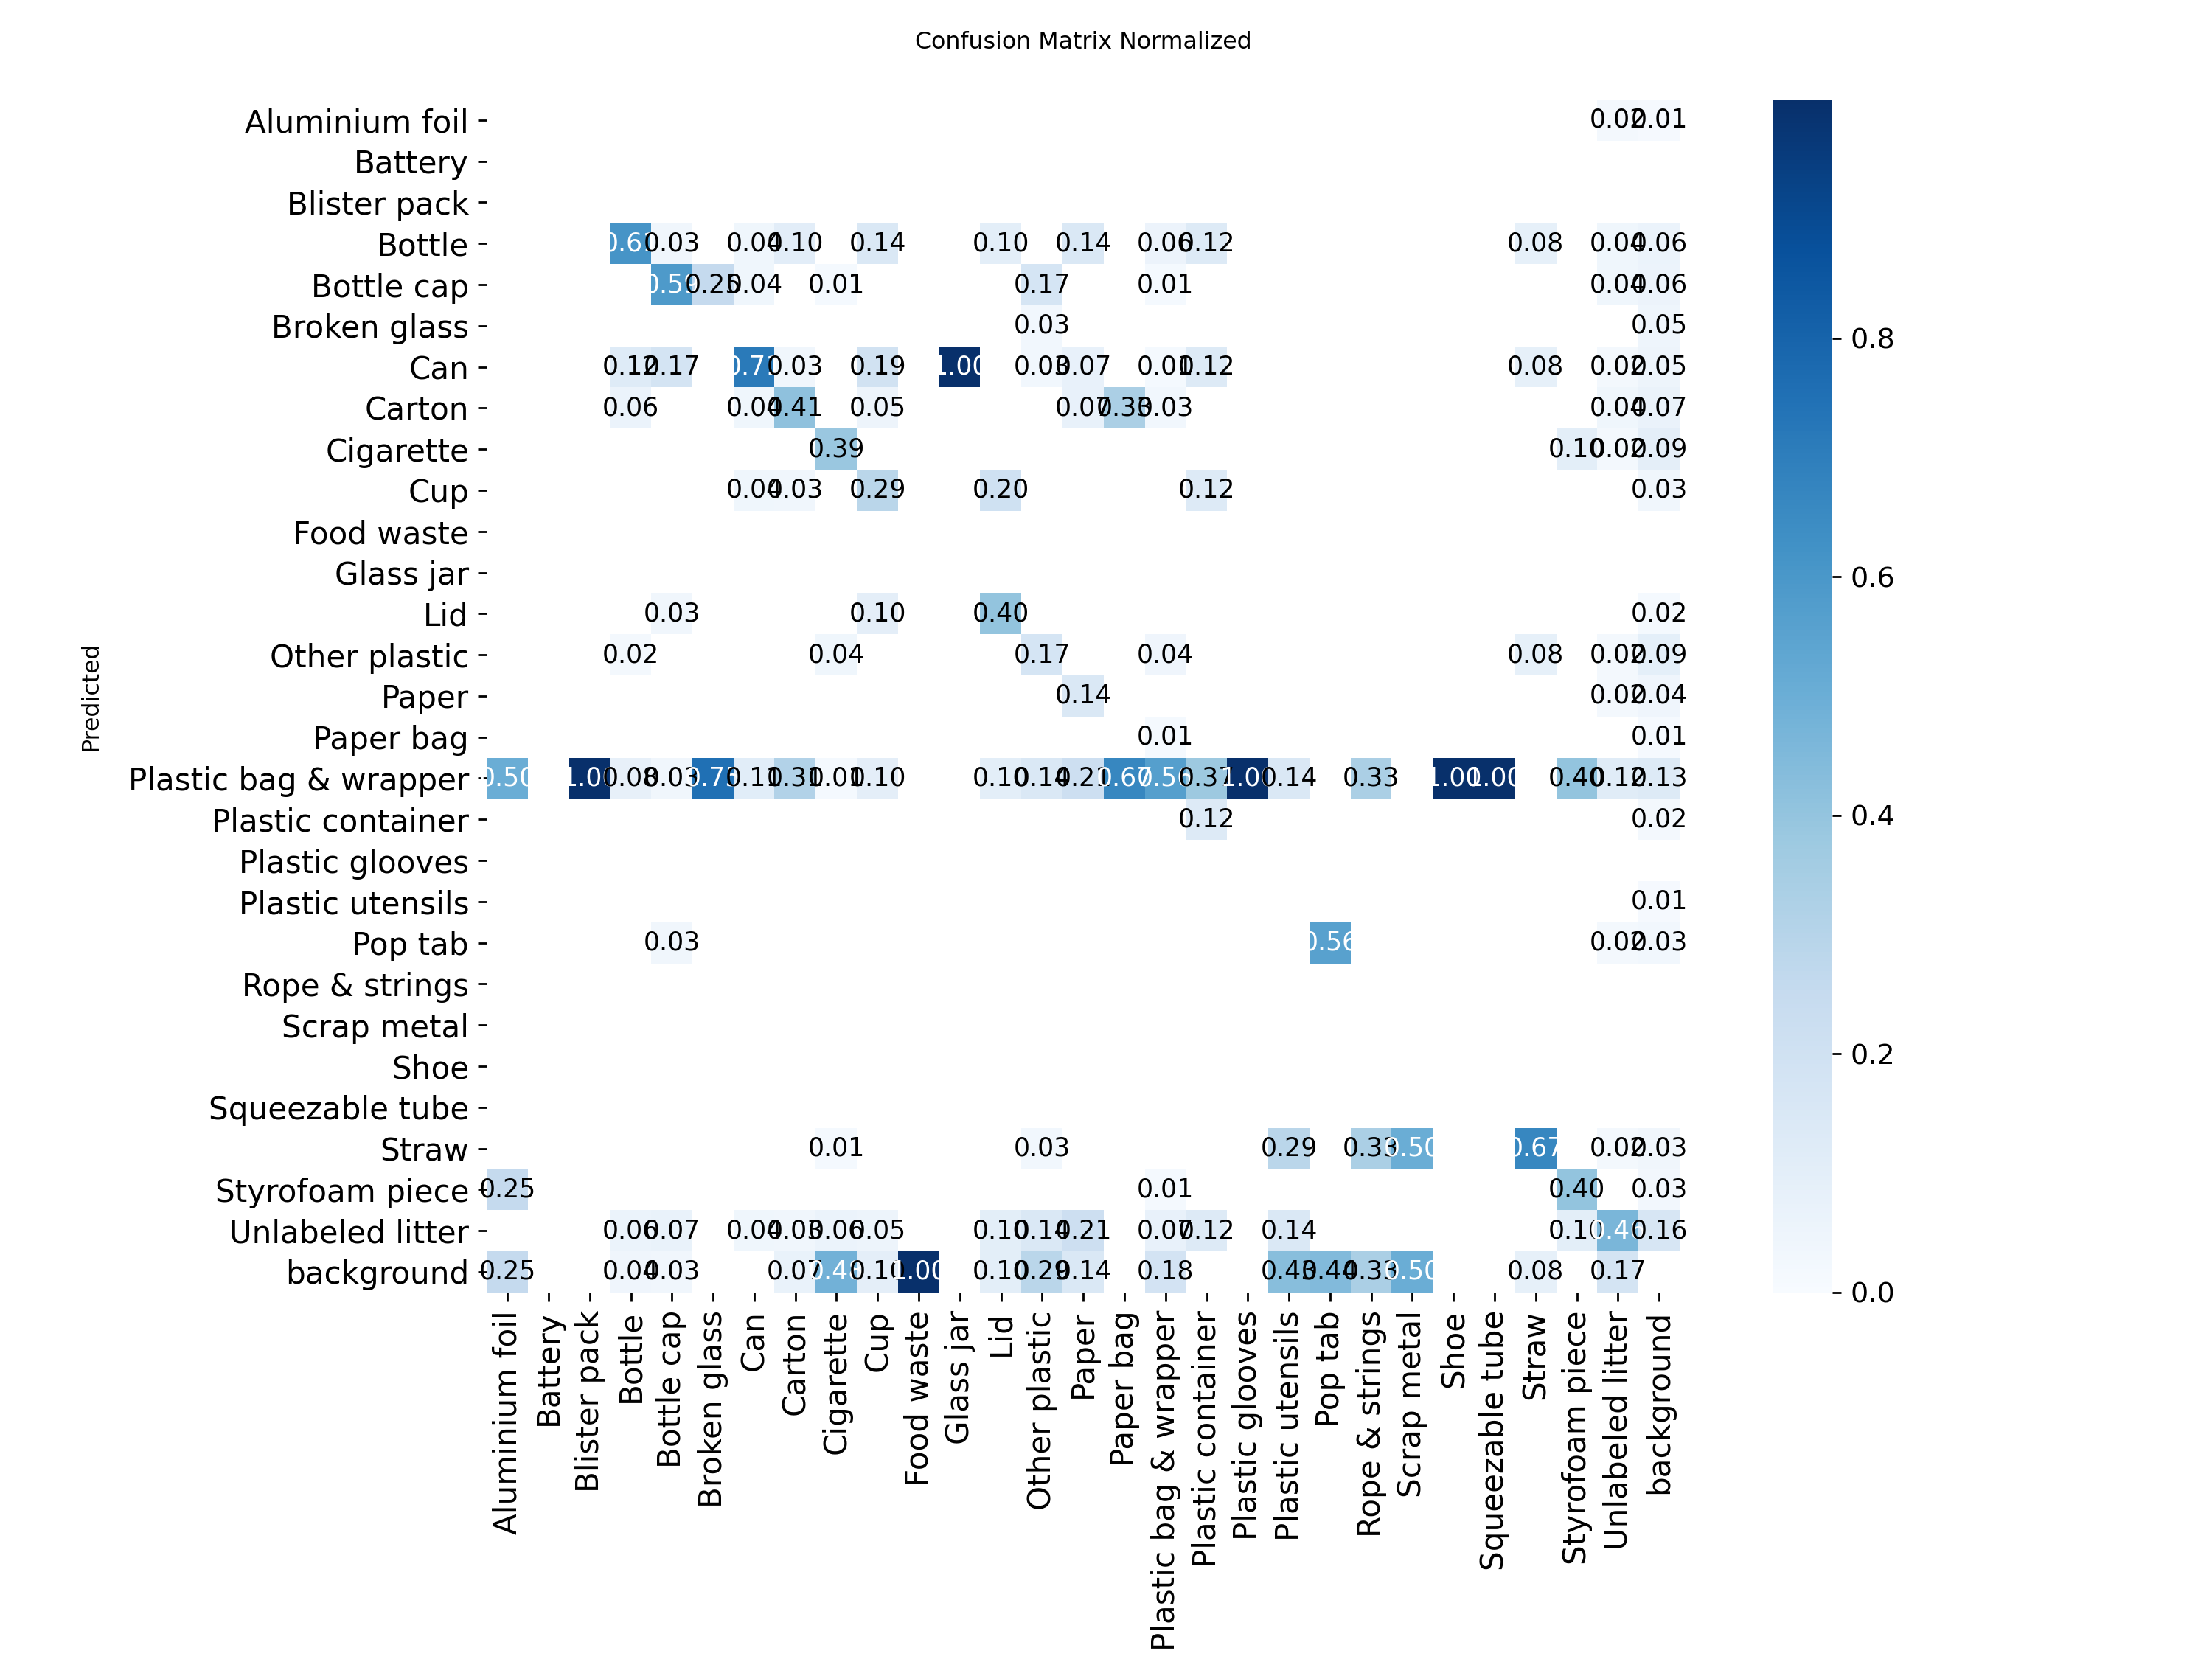

In [24]:
from IPython.display import Image as IPImage, display
for f in ["confusion_matrix_normalized.png", "PR_curve.png"]:
    p = Path(metrics.save_dir) / f
    if p.exists(): display(IPImage(filename=str(p), width=700))

## 8. Inferenz & Export

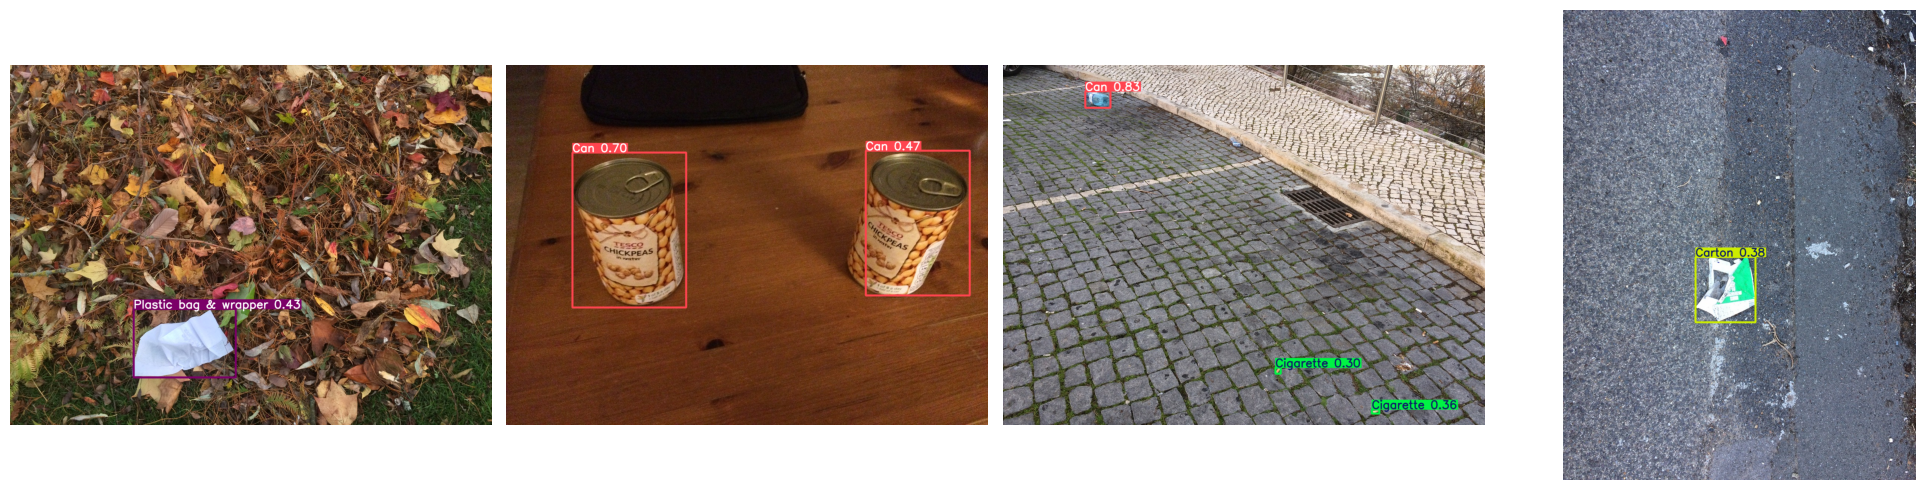

In [25]:
test_imgs = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))
preds = best.predict(random.sample(test_imgs, 4), imgsz=IMGSZ, conf=0.25, verbose=False)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, r in zip(axes, preds):
    ax.imshow(r.plot()[..., ::-1]); ax.axis("off")
plt.tight_layout(); plt.show()

In [26]:
def detect(path, conf=0.25):
    # Eigene Bilder: gibt DataFrame mit Klasse, Konfidenz und Box (Pixel) zurück
    r = best.predict(path, imgsz=IMGSZ, conf=conf, verbose=False)[0]
    return pd.DataFrame({
        "class": [CLASS_NAMES[int(c)] for c in r.boxes.cls],
        "conf": r.boxes.conf.cpu().numpy().round(3),
        **{k: v for k, v in zip(["x1", "y1", "x2", "y2"], r.boxes.xyxy.cpu().numpy().T.round(1))},
    })

# detect("mein_foto.jpg")

In [27]:
# Export, z. B. für Edge-Deployment (ONNX Runtime, OpenVINO, TensorRT ...)
onnx_path = best.export(format="onnx", imgsz=IMGSZ, dynamic=False, simplify=True)
print(onnx_path)

Ultralytics 8.4.215 🚀 Python-3.13.9 torch-2.10.0+cu128 CPU (AMD Ryzen 9 7900X3D 12-Core Processor)
YOLO11s summary (fused): 100 layers, 9,423,636 parameters, 0 gradients, 55.5 GFLOPs

PyTorch: starting from '/mnt/NVME/bjoern/TACO-WESORT.AI/taco_work/runs/taco_super_yolo11s/weights/best.pt' with input shape (1, 3, 1024, 1024) BCHW and output shape(s) (1, 32, 21504) (18.4 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/8.9 MB ? eta -:--:--
   ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/8.9 MB 4.4 MB/s eta 0:00:02
   ━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/8.9 MB 4.8 MB/s eta 0:00:02
   ━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/8.9 MB 4.9 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━ 3.7/8.9 MB 4.9 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━

## 9. Nächste Schritte zur Verbesserung
- **Klassen-Granularität** an den Use Case anpassen (`CLASS_MODE`): binär `litter` liefert deutlich höhere mAP als 28 Superkategorien.
- **Mehr Daten:** TACO bietet zusätzlich inoffizielle Annotationen (`annotations_unofficial.json`, ohne Review); weitere Müll-Datensätze ergänzen.
- **Kleine Objekte:** `imgsz=1280` oder Tiling/SAHI (Sliced Inference).
- **Long Tail:** gezielt seltene Klassen nachannotieren (siehe Plot AP vs. n_train), Copy-Paste-Augmentierung über die TACO-Segmentierungsmasken (`model=yolo11s-seg.pt` für Instance Segmentation).
- **Robuste Bewertung:** wegen der kleinen Testmenge mehrere Seeds/Splits (k-fold) laufen lassen und Mittelwert ± Streuung berichten.